# Cluster Sample Gallery

For every cluster, **n example days** shown as maps, **one row per variable** —
alongside the cluster's mean composite so you can see how much any single day
departs from the regime it was assigned to.

This notebook is **run-agnostic**. It discovers every trained run from
`checkpoint/*/params-*.yaml`, so a run trained tomorrow with four variables and
30 prototypes needs no edit here. Pick a run by setting `RUN` in the config cell,
or drive it from the shell without touching the file:

```bash
RUN=temperature-era-amazonia-15-anom N_SAMPLES=6 \
  .venv/bin/jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=7200 notebooks/cluster_samples.ipynb
```

Figures are also written to `figures/cluster_samples/<RUN>/` as one PNG per
cluster, so they can be dropped straight into the paper or a slide deck.

**Scope note:** the gallery uses the **training** days (the validation years are
held out of `dataset.imgs` and are stored already-transformed, so they have no
native-resolution map to plot). That is the same convention the composites in
`analysis_significance*.ipynb` use.

## Configuration

In [1]:
import os, sys, glob
if '..' not in sys.path:
    sys.path.append('..'); os.chdir('..')
import numpy as np, pandas as pd, torch, yaml
import matplotlib.pyplot as plt
from pathlib import Path

import src.inference as inf

# --- every trained run, discovered rather than hard-coded -------------------- #
RUNS = {Path(p).parent.name: p for p in sorted(glob.glob('checkpoint/*/params-*.yaml'))}
print('runs available:')
for r in RUNS: print('   ', r)

RUN = os.environ.get('RUN', 'temp-prep-era-amazonia-15-anom')
assert RUN in RUNS, f'unknown RUN={RUN!r}; pick one of {list(RUNS)}'
CONFIG = RUNS[RUN]
SAVE   = f'results/{RUN}'

# Prefer the best-validation checkpoint when the run saved one: for early-stopped
# runs '-latest' is the *worse* final epoch.
_best = f'checkpoint/{RUN}/{RUN}-best.pth.tar'
MODEL_SUFFIX = os.environ.get('MODEL_SUFFIX',
                              '-best.pth.tar' if os.path.exists(_best) else '-latest.pth.tar')

N_SAMPLES = int(os.environ.get('N_SAMPLES', 6))
# how the n days are chosen from each cluster:
#   representative - the n days closest to the prototype (cleanest examples)
#   spread         - evenly spaced from most to least typical (shows the range)
#   random         - a seeded random draw (unbiased look at the cluster)
PICK = os.environ.get('PICK', 'representative')
SEED = int(os.environ.get('SEED', 0))
# Percentile that sets each variable's colour limits. Precipitation has a very
# heavy tail (skew ~+4), so at 99 the rare extremes set the scale and ordinary
# wet/dry days look washed out — drop to ~95 to bring the bulk of the field out.
VABS_PCT = float(os.environ.get('VABS_PCT', 98))

OUT = Path(f'figures/cluster_samples/{RUN}')
OUT.mkdir(parents=True, exist_ok=True)
print(f'\nRUN={RUN}\nconfig={CONFIG}\ncheckpoint suffix={MODEL_SUFFIX}\n'
      f'n={N_SAMPLES} pick={PICK}\nfigures -> {OUT}/')

runs available:
    temp-prep-era-amazonia-15-anom
    temperature-era-amazonia-15-anom
    temperature-era-amazonia-15
    temperature-era-amazonia

RUN=temperature-era-amazonia-15-anom
config=checkpoint/temperature-era-amazonia-15-anom/params-temperature-era-amazonia-15-anom.yaml
checkpoint suffix=-best.pth.tar
n=6 pick=representative
figures -> figures/cluster_samples/temperature-era-amazonia-15-anom/


## Load the run

In [2]:
params, dataset = inf.read_data(CONFIG, validation=True)
encoder, prot = inf.load_model(params, model_suffix=MODEL_SUFFIX)
F = inf.get_model_results(read_path=SAVE, params=params, dataset=dataset,
                          encoder=encoder, prototypes=prot)[1]

N = params['criterion']['num_proto']
imgs = dataset.imgs                      # (T,V,H,W) native resolution, train days
cid  = F.argmax(1).cpu().numpy()
time = pd.to_datetime(dataset.time)
vars_names = params['data']['surf_vars']
V, H, W = imgs.shape[1:]
lat_lim = params['data']['lat_limit']; lon_lim = params['data']['lon_limit']
EXTENT = [min(lon_lim), max(lon_lim), min(lat_lim), max(lat_lim)]
IS_ANOM = params['data'].get('deseason_standardize', False)

# Per-variable presentation. Unknown variables fall back to a diverging temperature
# style, so a future run with new channels still plots.
VAR_META = {
    'mn2t': dict(label='T$_{min}$', cmap='RdBu_r', unit='K',      anom_unit='σ'),
    'mx2t': dict(label='T$_{max}$', cmap='RdBu_r', unit='K',      anom_unit='σ'),
    'tp':   dict(label='Precip.',   cmap='BrBG',   unit='mm/day', anom_unit='σ'),
}
meta = [VAR_META.get(v, dict(label=v, cmap='RdBu_r', unit='', anom_unit='σ'))
        for v in vars_names]

print(f'variables : {vars_names}  (V={V})')
print(f'clusters  : {N}   occupied: {len(np.unique(cid))}')
print(f'days      : {len(cid)}   {time[0].date()} -> {time[-1].date()}')
print(f'fields    : {"deseasonalised anomalies (σ)" if IS_ANOM else "raw units"}')

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_e7711dba3b5c50b3.pt


INFO:root:applied per-month per-cell deseasonalised standardisation (anomalies)


INFO:root:data loader created


Loaded E and F from results/temperature-era-amazonia-15-anom
variables : ['mn2t', 'mx2t']  (V=2)
clusters  : 15   occupied: 15
days      : 15340   1981-01-01 -> 2022-12-31
fields    : deseasonalised anomalies (σ)


In [3]:
# Raw (non-deseasonalised) fields so every sample can be annotated in physical
# units even when the model sees anomalies. Hits the same daily cache -> fast.
from src.data_manager import Era5Dataset
raw_ds = Era5Dataset(transform=None, surf_vars=vars_names,
                     lat_lim=lat_lim, lon_lim=lon_lim, split_val=True,
                     val_years=tuple(params['data']['val_years']),
                     deseason_standardize=False)
assert raw_ds.imgs.shape[0] == len(cid), 'raw fields must align with cluster assignments'
dm_raw = raw_ds.imgs.mean((2, 3)).numpy()      # (T,V) domain-mean in K / mm per day
print('raw domain-mean per variable:',
      {meta[v]['label']: round(float(dm_raw[:, v].mean()), 2) for v in range(V)})

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_e7711dba3b5c50b3.pt


raw domain-mean per variable: {'T$_{min}$': 294.47, 'T$_{max}$': 301.94}


## Cluster overview

In [4]:
rows = []
for k in range(N):
    m = cid == k
    rows.append(dict(cluster=k, n_days=int(m.sum()), freq_pct=round(m.mean()*100, 1),
                     **{f'{meta[v]["label"]}_field': round(float(imgs[m][:, v].mean()), 2)
                        for v in range(V)},
                     **{f'{meta[v]["label"]}_raw': round(float(dm_raw[m][:, v].mean()), 2)
                        for v in range(V)}))
overview = pd.DataFrame(rows).set_index('cluster')
print(overview.to_string())
empty = [k for k in range(N) if (cid == k).sum() == 0]
if empty: print('\nWARNING: clusters with no assigned day (collapsed prototypes):', empty)

         n_days  freq_pct  T$_{min}$_field  T$_{max}$_field  T$_{min}$_raw  T$_{max}$_raw
cluster                                                                                  
0          1086       7.1             0.81             0.33         295.22         302.30
1          1135       7.4             0.43             0.58         294.65         303.12
2           854       5.6            -0.32            -0.15         293.95         301.84
3           945       6.2            -1.01            -0.47         293.85         301.05
4          1100       7.2             0.34            -0.03         294.81         301.79
5           970       6.3            -0.35            -0.38         294.19         301.34
6           970       6.3             1.05             0.85         295.45         303.47
7           977       6.4            -0.06            -0.10         294.70         301.60
8           940       6.1             0.34             0.13         294.82         302.05
9         

## The gallery

One figure per cluster: **rows = variables**, **first column = the cluster mean
composite**, then the `N_SAMPLES` example days.

All panels of a given variable share one symmetric colour scale (fixed across
*all* clusters), so colours are comparable everywhere in the notebook. The mean
column will usually look fainter than the individual days — that is real, not a
plotting artefact: averaging cancels the day-to-day noise, and the gap between
the two is a visual read on within-cluster spread.

In [5]:
rng = np.random.default_rng(SEED)

def pick_indices(k, n=N_SAMPLES, how=PICK):
    idx = np.where(cid == k)[0]
    if idx.size == 0:
        return idx
    score = F[idx, k].cpu().numpy()
    order = idx[np.argsort(-score)]                       # most typical first
    if how == 'representative':
        sel = order[:n]
    elif how == 'spread':
        sel = order[np.linspace(0, order.size - 1, min(n, order.size)).astype(int)]
    elif how == 'random':
        sel = rng.choice(idx, size=min(n, idx.size), replace=False)
        sel = sel[np.argsort(-F[sel, k].cpu().numpy())]
    else:
        raise ValueError(f'unknown PICK={how!r}')
    return sel

# One symmetric scale per variable, shared by every cluster in the notebook.
samples_all = np.concatenate([pick_indices(k) for k in range(N) if (cid == k).any()])
VABS = np.array([max(np.percentile(np.abs(imgs[samples_all][:, v].numpy()), VABS_PCT), 1e-6)
                 for v in range(V)])
print(f'colour limits per variable (p{VABS_PCT:g}):',
      {meta[v]['label']: round(float(VABS[v]), 2) for v in range(V)})
print('lower VABS_PCT if a channel looks washed out (heavy-tailed fields like tp)')

def gallery(k, n=N_SAMPLES, how=PICK, save=True):
    sel = pick_indices(k, n, how)
    if sel.size == 0:
        print(f'cluster {k}: no days assigned'); return None
    ncol = len(sel) + 1
    fig, axes = plt.subplots(V, ncol, figsize=(1.95*ncol, 2.25*V), squeeze=False)
    comp = imgs[cid == k].mean(0).numpy()
    for v in range(V):
        panels = [comp] + [imgs[i].numpy() for i in sel]
        for c, arr in enumerate(panels):
            ax = axes[v][c]
            im = ax.imshow(arr[v], cmap=meta[v]['cmap'], vmin=-VABS[v], vmax=VABS[v],
                           extent=EXTENT, origin='upper', aspect='auto')
            ax.set_xticks([]); ax.set_yticks([])
            if v == 0:
                ax.set_title('MEAN\n(n=%d)' % (cid == k).sum() if c == 0
                             else f'{time[sel[c-1]].date()}\nsim {F[sel[c-1], k]:.2f}',
                             fontsize=7.5)
            if c == 0:
                ax.set_ylabel(meta[v]['label'], fontsize=10)
            else:
                # physical value of this day, so anomaly maps stay interpretable
                ax.text(.5, .02, f'{dm_raw[sel[c-1], v]:.1f} {meta[v]["unit"]}',
                        transform=ax.transAxes, ha='center', va='bottom', fontsize=6.5,
                        bbox=dict(fc='white', ec='none', alpha=.65, pad=1))
        fig.colorbar(im, ax=[axes[v][c] for c in range(ncol)], shrink=.85,
                     label=meta[v]['anom_unit'] if IS_ANOM else meta[v]['unit'])
    fig.suptitle(f'{RUN} — cluster {k}   '
                 f'({(cid==k).mean()*100:.1f}% of days, n={(cid==k).sum()})   '
                 f'[{how}]', fontsize=11)
    if save:
        p = OUT / f'cluster_{k:02d}.png'
        fig.savefig(p, dpi=130, bbox_inches='tight')
    plt.show()
    return sel

colour limits per variable (p98): {'T$_{min}$': 2.64, 'T$_{max}$': 2.38}
lower VABS_PCT if a channel looks washed out (heavy-tailed fields like tp)


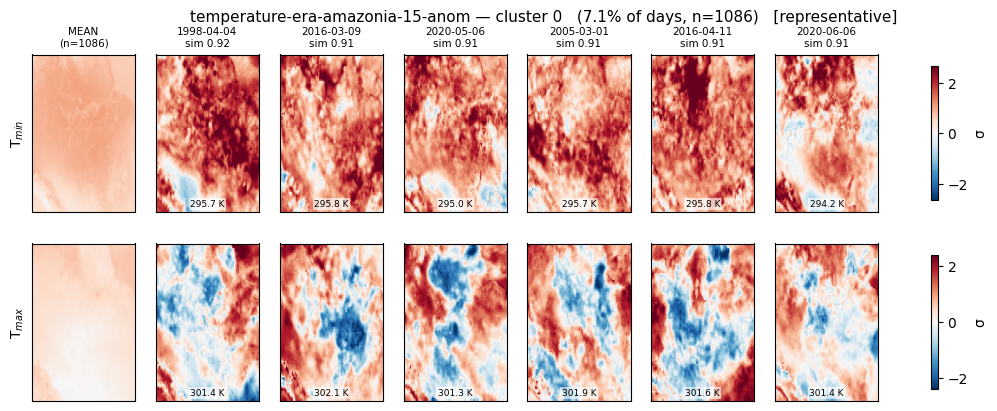

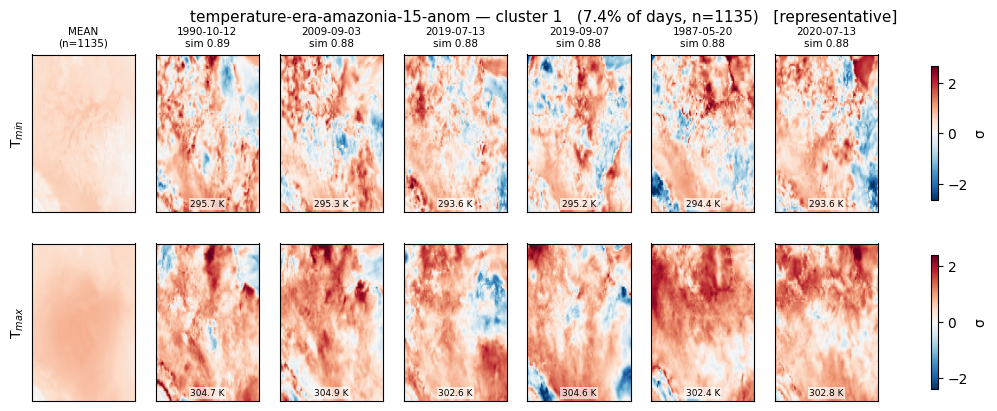

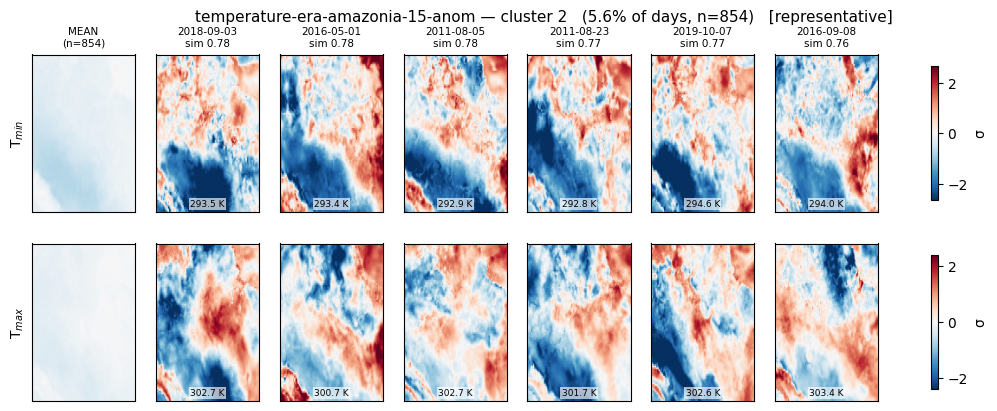

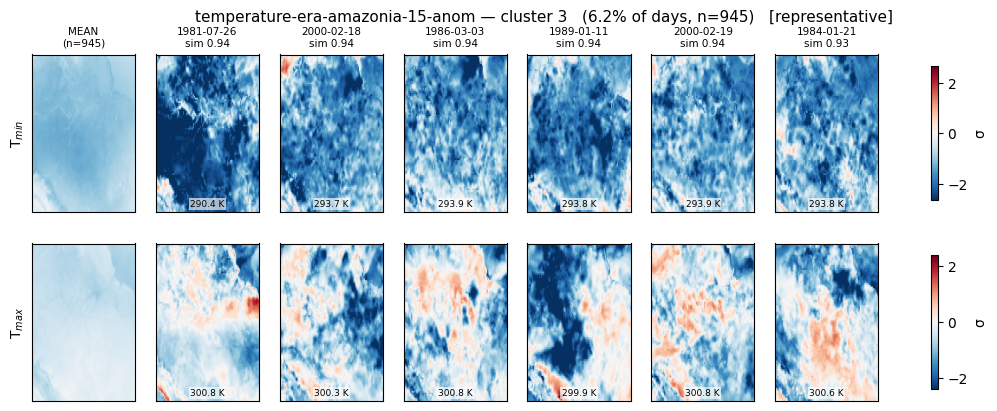

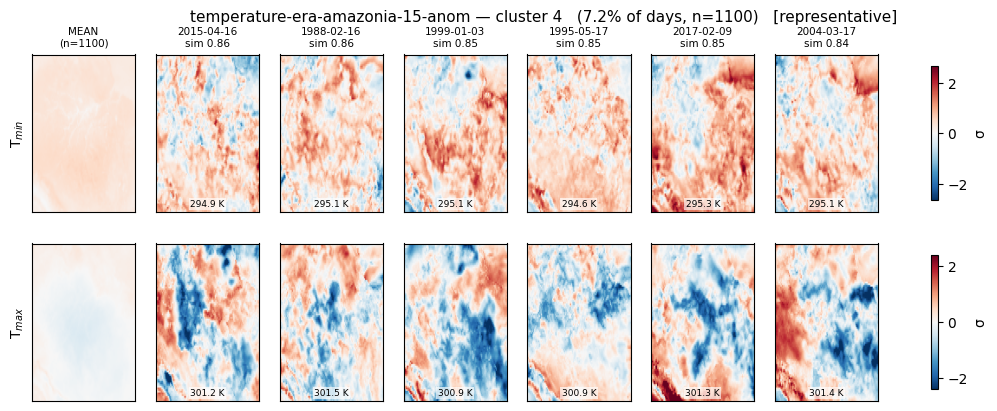

...

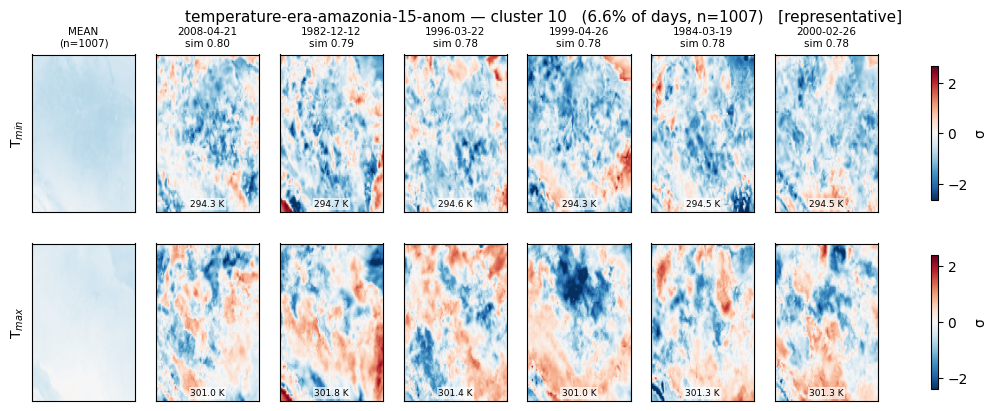

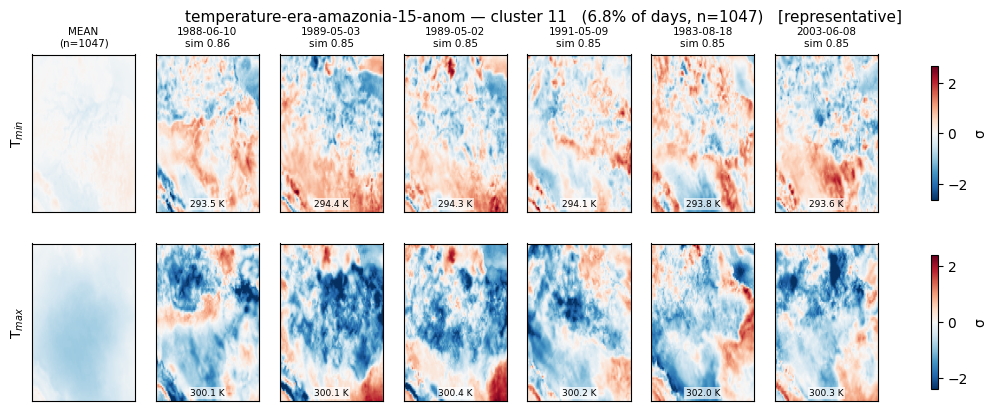

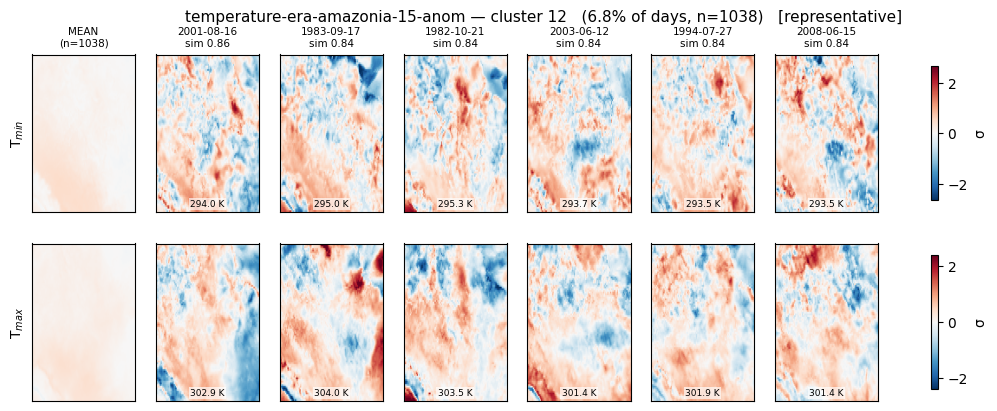

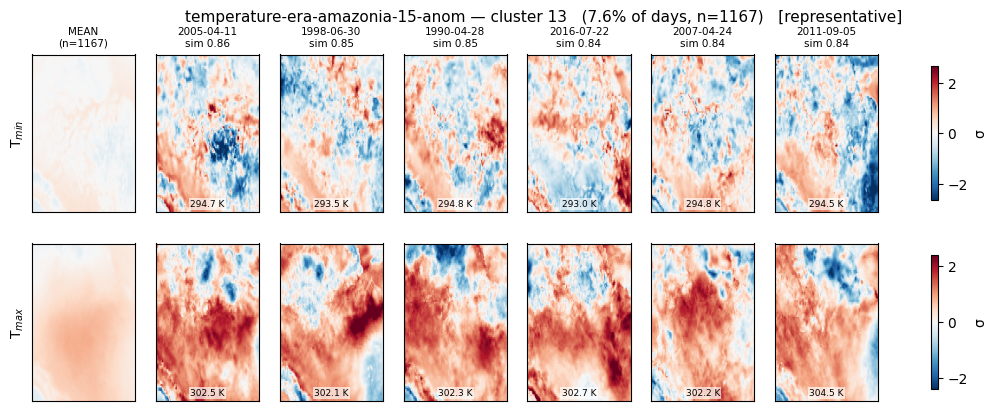

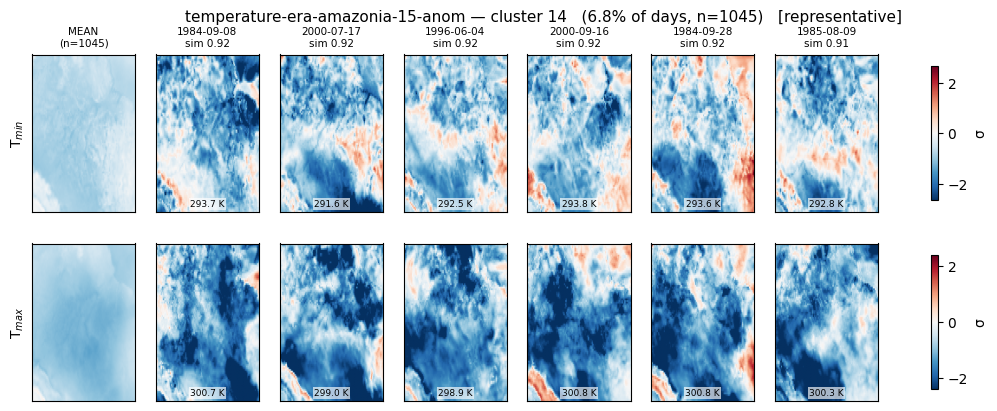

wrote: ['cluster_00.png', 'cluster_01.png', 'cluster_02.png', 'cluster_03.png', 'cluster_04.png', 'cluster_05.png', 'cluster_06.png', 'cluster_07.png', 'cluster_08.png', 'cluster_09.png', 'cluster_10.png', 'cluster_11.png', 'cluster_12.png', 'cluster_13.png', 'cluster_14.png']


In [6]:
for k in range(N):
    gallery(k)
print('wrote:', sorted(p.name for p in OUT.glob('cluster_*.png')))

## Contact sheet — every cluster on one page

The same days, one compact row per cluster, for a single variable at a time.
Useful for spotting near-duplicate clusters at a glance.

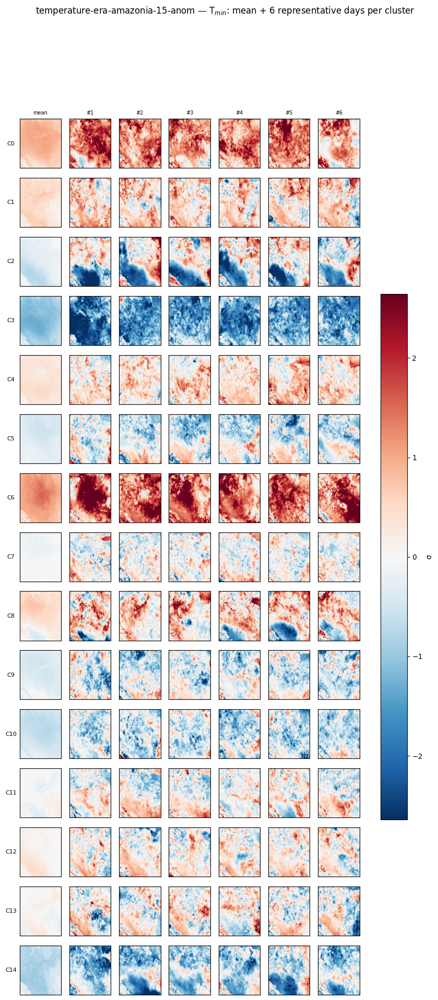

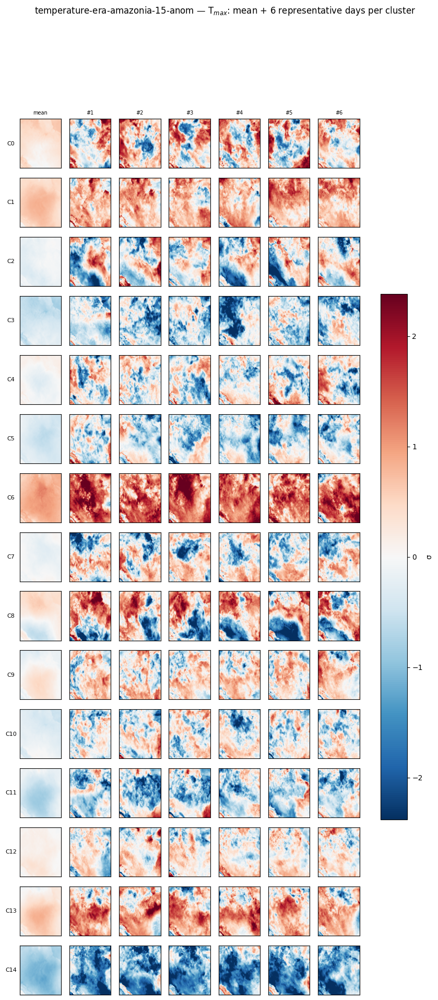

wrote: ['contact_mn2t.png', 'contact_mx2t.png']


In [7]:
def contact_sheet(v, how=PICK, n=min(N_SAMPLES, 6), save=True):
    live = [k for k in range(N) if (cid == k).any()]
    fig, axes = plt.subplots(len(live), n + 1, figsize=(1.5*(n+1), 1.45*len(live)),
                             squeeze=False)
    for r, k in enumerate(live):
        sel = pick_indices(k, n, how)
        panels = [imgs[cid == k].mean(0).numpy()] + [imgs[i].numpy() for i in sel]
        for c, arr in enumerate(panels):
            ax = axes[r][c]
            im = ax.imshow(arr[v], cmap=meta[v]['cmap'], vmin=-VABS[v], vmax=VABS[v],
                           extent=EXTENT, origin='upper', aspect='auto')
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0: ax.set_title('mean' if c == 0 else f'#{c}', fontsize=7)
            if c == 0: ax.set_ylabel(f'C{k}', fontsize=8, rotation=0, labelpad=12, va='center')
        for c in range(len(panels), n + 1):
            axes[r][c].axis('off')
    fig.colorbar(im, ax=axes, shrink=.6,
                 label=meta[v]['anom_unit'] if IS_ANOM else meta[v]['unit'])
    fig.suptitle(f'{RUN} — {meta[v]["label"]}: mean + {n} {how} days per cluster',
                 fontsize=12)
    if save:
        fig.savefig(OUT / f'contact_{vars_names[v]}.png', dpi=130, bbox_inches='tight')
    plt.show()

for v in range(V):
    contact_sheet(v)
print('wrote:', sorted(p.name for p in OUT.glob('contact_*.png')))

## Re-picking without re-running everything

`gallery()` and `contact_sheet()` take their own arguments, so you can inspect a
single cluster a different way without touching the config cell:

```python
gallery(5, n=10, how='spread')      # 10 days spanning typical -> atypical
gallery(5, how='random', save=False) # unbiased draw, not written to disk
contact_sheet(0, how='random')       # first variable, random days
```

To regenerate the whole gallery for another run, set `RUN` (see the header) and
re-run the notebook — nothing else is run-specific.